# Automated 3D segmentation of guard cells — pretrained 3D CellNet inference

**Paper**: Davaasuren D., Chen Y., Jaafar L., Marshall R., Dunham A.L., Anderson C.T., Wang J.Z. (2022) *Automated 3D segmentation of guard cells enables volumetric analysis of stomatal biomechanics.* **Patterns** 3(12):100627. [DOI 10.1016/j.patter.2022.100627](https://doi.org/10.1016/j.patter.2022.100627) (open-access copy: [PMC9782259](https://pmc.ncbi.nlm.nih.gov/articles/PMC9782259/))

**Author code**: [Dolzodmaa/GuardCellSegmentation](https://github.com/Dolzodmaa/GuardCellSegmentation) commit `076ffaf8e53c02a0cf44cd9c1c997936e5f4bf92` (MIT). **Data & checkpoints**: Mendeley Data [10.17632/2dvtw8cyhx.1](https://doi.org/10.17632/2dvtw8cyhx.1) (CC BY 4.0).

**Scope** (one-example reproduction, inference-first): load the authors' published pretrained 3D CellNet checkpoints (patch 128 + patch 256, late fusion exactly as in the README's `--both_models` path of `predict.py`) and segment guard cells in **one 3D confocal TIFF volume**, producing an instance-separated guard-cell map and per-instance volume measurements (`prediction.tif`, `labels.tif`, `result.tif`). Two samples are used:

1. `img_test/1-1 after.tif` — the author-documented example input;
2. `img_train/13.tif` with the expert annotation `img_label/label-13.tif` — for a predicted-vs-reference IoU/Dice plausibility check (**a training sample, not a test benchmark**).

**Not reproduced** (out of scope): training, cross-validation, baseline comparisons, Slicer3D visualization, biomechanics statistics. A single-example run does **not** verify the paper's dataset-level accuracy (mIoU 0.824).

**Execution status**: this notebook was executed top-to-bottom on fresh Google Colab runtimes; the saved outputs below come from those runs. The reported runtime (CPU or T4 GPU) is stated in the *Validation record* section at the end.

**AI 補助に関する注意 / AI-assisted adaptation notice**: The scientific code is the authors' own pinned code, reused verbatim except for five small, printed compatibility repairs (Keras-2 binding via `tf_keras`, removal of the training-only `patchify` import, a `tifffile.imsave` shim, the patch-256 input shape of the authors' `--both_models` branch, and a per-slice OpenCV morphology opening where the authors' invalid 3D `cv2.morphologyEx` call is repaired with their exact 2D kernel). The notebook scaffolding around the authors' functions is AI-generated; untested behavior beyond the executed examples is not guaranteed.

（本ノートブックは著者の pinned コードをそのまま利用し、互換性のための 5点の小さな修正（表示付き）のみを施しています。周辺の説明・可視化コードは AI が作成しました。）

## Runtime selection & how to run

**Select `Runtime` → `Change runtime type`: a T4 GPU is recommended (the paper reports 26.7 s/image on a V100 vs 177.2 s on CPU), but the same notebook also runs on a plain CPU runtime — only slower.** Then `Runtime` → `Run all`. Total downloads are ≈ 1.1 GB (two 448 MB checkpoints, a 45 MB ImageNet encoder, and 33 MB of sample volumes). On a T4 the notebook completes in roughly 5–10 minutes; on CPU allow 15–60 minutes depending on the allocated cores. No Drive mount, no login, no API key is needed.

**実行時間の目安**: T4 GPU 推奨（約5〜10分）。CPU でも動作しますが 15〜60 分かかることがあります。ダウンロード量は約 1.1 GB です。

Print the platform this run is executing on (CPU cores/RAM, or an allocated GPU). The author code targets the Keras 2 API, which we bind to the `tf-keras` package in a later cell (see the printed diff there); no environment flag is needed.

実行環境の情報を表示します。著者コードは Keras 2 API 前提のため、 後のセルで `tf-keras` パッケージに接続します（環境フラグは不要）。

In [ ]:
import sys, platform
print('python', sys.version)
print('platform', platform.platform())
import psutil
print('CPUs', psutil.cpu_count(), '| RAM GB', round(psutil.virtual_memory().total/2**30, 1))

python 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
platform Linux-6.6.159+-x86_64-with-glibc2.39
CPUs 2 | RAM GB 12.7


Install the missing dependencies of the author import graph. Colab already provides TensorFlow, opencv, scikit-image, pandas and matplotlib; we add only `tf-keras`, `keras-applications`, `connected-components-3d` and `tifffile`. `patchify` is deliberately **not** installed: its current releases pin `numpy<2` / `scikit-image<0.18`, which cannot coexist with Colab's stack — and it is only used by the authors' *training* helper `make_patches`, never by the inference path (documented below).

著者コードの依存のうち欠けているもののみインストールします。 `patchify` は学習用ヘルパー専用かつ依存関係が競合するため除外します。

In [ ]:
import importlib.util, sys, subprocess
def have(m):
    return importlib.util.find_spec(m) is not None
missing = [m for m in ['cv2', 'skimage', 'pandas', 'matplotlib', 'scipy'] if not have(m)]
print('preinstalled check, missing:', missing)
pkgs = ['tf-keras', 'keras-applications',
        'connected-components-3d', 'tifffile'] + missing
print('installing:', pkgs)
r = subprocess.run([sys.executable, '-m', 'pip', 'install', '--timeout', '120'] + pkgs,
                   capture_output=True, text=True)
if r.returncode != 0:
    print(r.stdout[-4000:]); print(r.stderr[-4000:])
    raise RuntimeError(f'pip install failed with exit {r.returncode}')
print('pip ok')

preinstalled check, missing: []
installing: ['tf-keras', 'keras-applications', 'connected-components-3d', 'tifffile']


pip ok


Verify the TensorFlow / tf-keras versions and enable memory growth on any allocated GPU. On a CPU runtime the GPU list is empty and the notebook continues unchanged — the authors' inference code is device-agnostic.

TensorFlow / tf-keras のバージョンを確認し、GPU があればメモリ成長を有効化します（GPU がなくてもそのまま実行できます）。

In [ ]:
import tensorflow as tf
import tf_keras, numpy
print('tensorflow', tf.__version__, '| tf_keras', tf_keras.__version__)
gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
print('GPUs:', gpus)
print('numpy', numpy.__version__)

tensorflow 2.21.0 | tf_keras 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
numpy 2.1.3


## Author code acquisition (pinned commit)

Download the 10 inference-path files from the authors' repository at the pinned commit and verify every SHA-256. The recorded hashes are those of the exact blobs at commit
`076ffaf8e53c02a0cf44cd9c1c997936e5f4bf92` (main branch, MIT licence).

著者リポジトリの pinned commit から推論に必要な 10 ファイルを取得し、 SHA-256 を検証します。

In [ ]:
import hashlib, urllib.request, pathlib
REPO = 'Dolzodmaa/GuardCellSegmentation'
COMMIT = '076ffaf8e53c02a0cf44cd9c1c997936e5f4bf92'
CODE_SHA256 = {'backbone.py': 'fbaeab86ce1932ac5f091b68a6a758a9668a2eb10f61b7e5ed470b1e3a1e1558', 'common.py': '01515bef91dc9305369339a1a79b602206e437192162ded0f9f0053e82b56b31', 'densenet.py': '64eb73bbea784e149e4f75f6cfe9c768328332958a0ed5d22d7b01730330b63d', 'helper.py': '135d48cabef67003866078710b0429a5b84a2b87d5eb11c6481d4496990cd463', 'loss.py': 'aa314f716ac10defd7be6b823ec815e06fc6e47edf272739d8b8413b08aa8c53', 'metrics.py': '2fbd68d5dac48ee87eda57417207b9afa05ef0b58d1bde76f40ca49a4f85b8fd', 'model.py': 'adecb065136c2201d785155e89bd3651838ff05850106475cb4992a5368fc267', 'predict.py': 'c24027db92db050584439594fa94ad8776ab9df155bbd69d9353539f32b51a94', 'utils.py': '96ff3d2fed4ccaddf2b6b739c0ec5355419282541be28ace3550f107c20f2d89', 'weights.py': '272ad30b8464c8b85427fb3cd3a368bf9dcd6b64e88418c62dbf9bc48d41fcd9'}
CODE_DIR = pathlib.Path('/content/gc3d_code'); CODE_DIR.mkdir(exist_ok=True)
for name, expect in CODE_SHA256.items():
    url = f'https://raw.githubusercontent.com/{REPO}/{COMMIT}/{name}'
    data = urllib.request.urlopen(url, timeout=120).read()
    got = hashlib.sha256(data).hexdigest()
    assert got == expect, (name, got)
    (CODE_DIR / name).write_bytes(data)
print(f'{len(CODE_SHA256)} author files verified at commit', COMMIT)
print(sorted(CODE_SHA256))

10 author files verified at commit 076ffaf8e53c02a0cf44cd9c1c997936e5f4bf92
['backbone.py', 'common.py', 'densenet.py', 'helper.py', 'loss.py', 'metrics.py', 'model.py', 'predict.py', 'utils.py', 'weights.py']


Apply the documented compatibility patches and print a unified diff of every change. No numerical operation is altered:

1. **Keras-2 binding** — the authors' code imports the Keras 2 API (`from tensorflow import keras`, `from keras import backend as K`, …). Colab's TF 2.21 maps `tensorflow.keras` to Keras 3, so the patched files import the maintained Keras-2 lineage package **`tf_keras`** directly (`import tf_keras as keras`, `from tf_keras import …`, and `import tf_keras as tf` + `tf.optimizers` in `predict.py`).
2. **`patchify` import removed** from `utils.py` — it is used only by the training-path helper `make_patches` (never called here) and its current releases pin `numpy<2` / `scikit-image<0.18`, which cannot coexist with Colab's stack.
3. **`tifffile.imsave` shim** — modern tifffile removed `imsave`; the shim delegates to the identical `tifffile.imwrite`.

互換性のための修正（Keras 2 系 `tf_keras` への接続、学習専用 patchify の 除去、tifffile.imsave の代替）を差分表示付きで適用します。数値演算は 変更しません。

In [ ]:
import difflib, re
IMSAVE_SHIM = (
    'import tifffile' + chr(10) +
    'def imsave(path, data):' + chr(10) +
    '    tifffile.imwrite(path, data)' + chr(10))
for name in ['model.py', 'predict.py', 'utils.py', 'backbone.py', 'common.py',
             'densenet.py', 'weights.py', 'helper.py', 'loss.py', 'metrics.py']:
    p = CODE_DIR / name
    text = p.read_text()
    changed = text.replace('from tensorflow.keras import', 'from tf_keras import') \
                   .replace('from keras import', 'from tf_keras import') \
                   .replace('from keras.models import', 'from tf_keras.models import') \
                   .replace('from tensorflow import keras', 'import tf_keras as keras')
    if name == 'utils.py':
        changed = changed.replace('from patchify import patchify, unpatchify' + chr(10), '')
    if name == 'predict.py':
        changed = changed.replace('from tifffile import imsave', IMSAVE_SHIM)
        changed = changed.replace('import tensorflow as tf', 'import tf_keras as tf')
        changed = changed.replace('tf.keras.optimizers', 'tf.optimizers')
        # OpenCV has no 3D morphology: the author call raises 'dims <= 2' on
        # any standard OpenCV. Repair: per-slice opening with the authors'
        # exact 5x5 cross kernel and iteration count.
        changed = re.sub(
            r'imageMorphOpened = cv2\.morphologyEx\(new,.*?iterations=it\)',
            'imageMorphOpened = np.zeros_like(new)' + chr(10) +
            '  for i in range(new.shape[0]):' + chr(10) +
            '    imageMorphOpened[i] = cv2.morphologyEx(new[i], cv2.MORPH_OPEN, element, iterations=it)',
            changed, flags=re.S)
    diff = difflib.unified_diff(text.splitlines(), changed.splitlines(), lineterm='', n=0)
    for line in list(diff)[2:]:
        print(line)
    p.write_text(changed)
print('compatibility patches applied')

@@ -19,2 +19,2 @@
-from tensorflow.keras import backend as K
-from keras import backend as K
+from tf_keras import backend as K
+from tf_keras import backend as K
@@ -23 +23 @@
-from tensorflow import keras
+import tf_keras as keras
@@ -6,3 +6,3 @@
-import tensorflow as tf
-from tensorflow.keras import backend as K
-from keras import backend as K
+import tf_keras as tf
+from tf_keras import backend as K
+from tf_keras import backend as K
@@ -11 +11,4 @@
-from tifffile import imsave
+import tifffile
+def imsave(path, data):
+    tifffile.imwrite(path, data)
+
@@ -17 +20 @@
-from keras.models import load_model
+from tf_keras.models import load_model
@@ -19 +22 @@
-from keras import backend as K
+from tf_keras import backend as K
@@ -58,2 +61,3 @@
-  imageMorphOpened = cv2.morphologyEx(new, cv2.MORPH_OPEN, 
-                          element,iterations=it)  
+  imageMorphOpened = np.zeros_like(new)
+  for i in range(new.shape[0]):
+    imageMorphOpened[i] = cv2.morphologyEx(new[i], cv2.MO

## Data & checkpoint acquisition (Mendeley 10.17632/2dvtw8cyhx.1, CC BY 4.0)

Download the two published checkpoints, the authors' documented test example (`img_test/1-1 after.tif`), one labeled training volume (`img_train/13.tif`) and its expert annotation (`img_label/label-13.tif`). File UUIDs and expected sizes/hashes come from the dataset's public record API (version 1, published 2023-09-15). Every byte is verified against the recorded SHA-256.

Mendeley データセット（CC BY 4.0）からチェックポイントとサンプルを取得し、 公開レコード API の SHA-256 と照合します。

In [ ]:
import hashlib, time, pathlib, requests
BASE = 'https://data.mendeley.com/public-files/datasets/2dvtw8cyhx/files'
ASSETS = {
    'model_128.hdf5': ('14374bce-b30a-4206-af83-ece0fd4dd947', 469855192, '631967e3f843a148f76bcd22b7ab0b1c7823d85a0efd8d6acd69b016b4e27b75'),
    'model_256.hdf5': ('0e0df2b3-0271-4767-9e46-dfbfb4b7c979', 469855192, '2883a22a67a35e1bc00f562e2f8ae747ff3a47f08fd0117a6bae6315391b47f8'),
    '1-1_after.tif': ('d952ed00-3e23-4c09-aa5b-b1d9e6b8bea0', 11569539, '1eb9061d73afab1ec08466e4b7fee4750bf02482e6f3fdd5cd5f67beab8c9d6f'),
    '13.tif': ('6c5888bc-3224-4ec8-9496-1d967b91bb4c', 20977345, 'a8aa442434af698817683ccc51a3e4c29c567e1b3a497be116f9913c35cec15b'),
    'label-13.tif': ('0259fdce-d838-4d46-9022-8fe3620d719c', 593259, '0b1213eb7b081b666eb5be6c485ec040ac1888830d0c99d81af4664441435add'),
}
DATA_DIR = pathlib.Path('/content/gc3d_data'); DATA_DIR.mkdir(exist_ok=True)
for name, (uuid_, size, expect) in ASSETS.items():
    dest = DATA_DIR / name
    if dest.exists() and dest.stat().st_size == size:
        print(name, 'already present'); continue
    t0 = time.time()
    with requests.get(f'{BASE}/{uuid_}/file_downloaded', stream=True, timeout=600,
                      headers={'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64) research-notebook'}) as r:
        r.raise_for_status()
        total = 0
        with open(dest, 'wb') as f:
            for chunk in r.iter_content(8 << 20):
                f.write(chunk); total += len(chunk)
                if total % (256 << 20) < (8 << 20):
                    print(f'  {name}: {total/2**20:.0f} MiB', flush=True)
    dt = time.time() - t0
    got = hashlib.sha256(dest.read_bytes()).hexdigest()
    assert got == expect and dest.stat().st_size == size, (name, got, dest.stat().st_size)
    print(f'{name}: {size} bytes sha256 ok ({dt:.0f}s, {size/2**20/dt:.0f} MiB/s)')

  model_128.hdf5: 256 MiB


model_128.hdf5: 469855192 bytes sha256 ok (19s, 23 MiB/s)


  model_256.hdf5: 256 MiB


model_256.hdf5: 469855192 bytes sha256 ok (19s, 24 MiB/s)


1-1_after.tif: 11569539 bytes sha256 ok (3s, 4 MiB/s)


13.tif: 20977345 bytes sha256 ok (3s, 7 MiB/s)


  label-13.tif: 1 MiB


label-13.tif: 593259 bytes sha256 ok (2s, 0 MiB/s)


## Input preview — labeled training volume with its expert reference annotation

Before any model runs, inspect the actual data. `13.tif` is one of the nine expert-labeled training volumes (confocal z-stack, plasma-membrane GFP); `label-13.tif` is the matching guard-cell annotation (guard cell vs background). The figure shows a mid-stack xy slice of the raw input and, below it, the same slice with the **reference annotation** outlined — the expert ground truth, not a model prediction.

モデル実行前に実データを確認します。上段は生入力の中央スライス、下段は 専門家による参照アノテーション（モデル予測ではなく正解）を重ねた表示です。

13.tif (20, 512, 512) float32 | label-13.tif (20, 512, 512) int16
label unique values: [0 1]


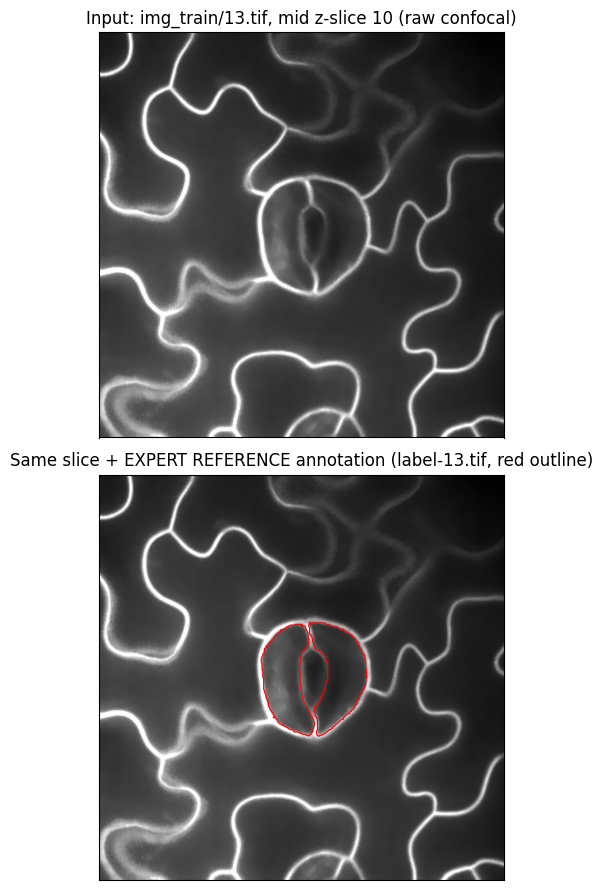

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tifffile
vol13 = tifffile.imread(str(DATA_DIR / '13.tif'))
lab13 = tifffile.imread(str(DATA_DIR / 'label-13.tif'))
print('13.tif', vol13.shape, vol13.dtype, '| label-13.tif', lab13.shape, lab13.dtype)
print('label unique values:', np.unique(lab13)[:10])
zmid = vol13.shape[0] // 2
slice13 = vol13[zmid]
lab_bin = (np.asarray(lab13) > 0)
fig, axes = plt.subplots(2, 1, figsize=(6, 9))
axes[0].imshow(slice13, cmap='gray')
axes[0].set_title(f'Input: img_train/13.tif, mid z-slice {zmid} (raw confocal)')
axes[1].imshow(slice13, cmap='gray')
axes[1].contour(lab_bin[zmid], levels=[0.5], colors='red', linewidths=0.8)
axes[1].set_title('Same slice + EXPERT REFERENCE annotation (label-13.tif, red outline)')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Input preview — author-documented test example

The README's inference command uses `img_test/1-1 after.tif` (an *after-ablation* stack from the biomechanics experiment). Show its shape and a mid-stack slice plus a max-intensity projection so the guard-cell structures are visible before inference.

README の推論コマンドが使用するテスト用ボリュームの中間スライスと 最大値投影を表示します。

1-1 after.tif (22, 512, 512) uint16 | intensity range: 0.0 65535.0


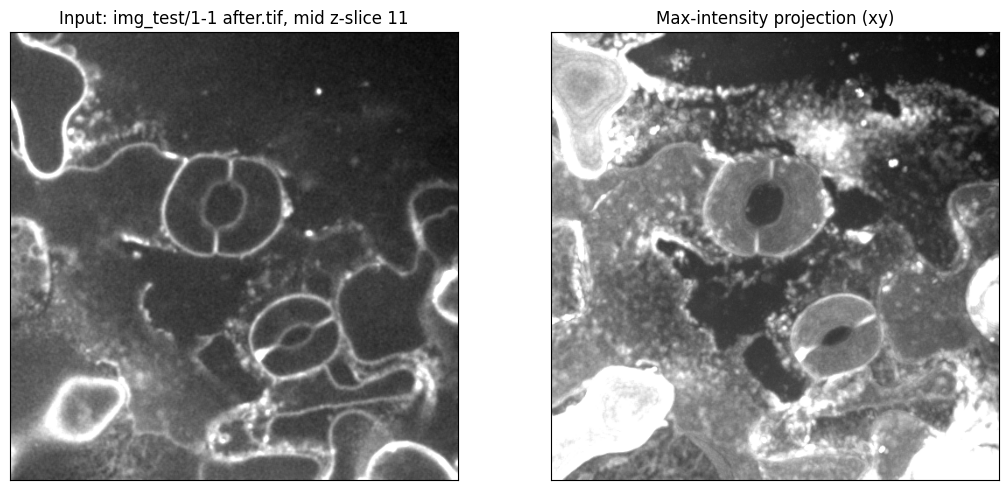

In [ ]:
vol1 = tifffile.imread(str(DATA_DIR / '1-1_after.tif'))
print('1-1 after.tif', vol1.shape, vol1.dtype, '| intensity range:', float(vol1.min()), float(vol1.max()))
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
z1 = vol1.shape[0] // 2
axes[0].imshow(vol1[z1], cmap='gray')
axes[0].set_title(f'Input: img_test/1-1 after.tif, mid z-slice {z1}')
axes[1].imshow(vol1.max(axis=0), cmap='gray')
axes[1].set_title('Max-intensity projection (xy)')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Model construction and checkpoint loading

Build both 3D CellNet models **exactly as the authors' `predict.py --both_models` branch does**: patch-wise attention-gated 3D U-Net (`model.py`) with a 3D DenseNet121 encoder whose ImageNet weights (`densenet121_inp_channel_3_tch_0_top_False.h5`, md5-pinned in the authors' `weights.py`) TensorFlow downloads automatically, then load the published checkpoints `model_128.hdf5` and `model_256.hdf5` on top. The encoder pretraining is subsequently overwritten by the checkpoint weights. One documented repair is required: the published `predict.py` builds the patch-256 model with a `(32, 128, 128, 3)` input shape (a copy-paste slip at lines 155–160 — feeding 256-patches then fails with a shape error). The checkpoint weights are input-size agnostic, so the patch-256 model is built with the intended `(32, 256, 256, 3)` input.

`predict.py --both_models` と同じ構成で両モデルを構築し、公開チェックポイント `model_128.hdf5` / `model_256.hdf5` を読み込みます（ImageNet 事前学習エンコーダは著者コードの md5 指定に従い自動取得）。 著者コードの patch-256 モデルの入力形状誤りは、意図された `(32,256,256,3)` に修正します（チェックポイント重みは入力サイズに非依存）。

In [ ]:
import sys, time
sys.path.insert(0, str(CODE_DIR))
for mod in ['model', 'predict', 'utils', 'loss', 'helper', 'metrics',
            'backbone', 'common', 'densenet', 'weights']:
    sys.modules.pop(mod, None)  # ensure the patched files are re-imported
import tf_keras
from model import Model
from loss import dice_loss, binary_focalloss
from metrics import iou_score, f1_score, precision, recall
optim = tf_keras.optimizers.Adam(0.0001)          # predict.py: LR = 0.0001
total_loss = dice_loss + (3 * binary_focalloss)   # predict.py: gamma = 3
t0 = time.time()
model1 = Model('densenet', classes=1, input_shape=(32, 128, 128, 3),
               encoder_weights='imagenet', activation='sigmoid', dropout=0.15)
model1.compile(optimizer=optim, loss=total_loss,
               metrics=[iou_score, f1_score, precision, recall])
model1.load_weights(str(DATA_DIR / 'model_128.hdf5'))
print('model_128 (patch 128) weights loaded in', round(time.time()-t0, 1), 's')
t0 = time.time()
# Documented repair: predict.py builds the 256-model with a (32,128,128,3)
# input (copy-paste slip); the checkpoint weights are input-size agnostic.
model2 = Model('densenet', classes=1, input_shape=(32, 256, 256, 3),
               encoder_weights='imagenet', activation='sigmoid', dropout=0.15)
model2.compile(optimizer=optim, loss=total_loss,
               metrics=[iou_score, f1_score, precision, recall])
model2.load_weights(str(DATA_DIR / 'model_256.hdf5'))
print('model_256 (patch 256) weights loaded in', round(time.time()-t0, 1), 's')

    8192/46616920 [..............................] - ETA: 0s

  311296/46616920 [..............................] - ETA: 9s

  835584/46616920 [..............................] - ETA: 6s

 1622016/46616920 [>.............................] - ETA: 4s

 2768896/46616920 [>.............................] - ETA: 3s

...

44777472/46616920 [===========================>..] - ETA: 0s

45924352/46616920 [============================>.] - ETA: 0s

46616920/46616920 [==============================] - 2s 0us/step


model_128 (patch 128) weights loaded in 7.3 s


model_256 (patch 256) weights loaded in 4.8 s


## Inference on the test example — patch-wise 3D prediction

Follow the authors' `predict.py`: normalize the volume to [0, 1], resize to the fixed (32, 512, 512) network input with `resize_to_512`, then run the authors' `get_prediction` — it slides a 3D patch window (patch 128, step 64 → 7×7 patches; patch 256, step 128 → 4×4 patches), stacks each patch to 3 channels, thresholds overlapping patch predictions at 0.5 and keeps the maximum probability for the fusion. Each call reports its elapsed time (paper reference: 26.7 s GPU / 177.2 s CPU per image).

著者の `predict.py` に従い、正規化→(32,512,512) へリサイズ→ `get_prediction` によるパッチごと推論を行います。

In [ ]:
from utils import resize_to_512, resize_back
from predict import get_prediction
z1 = vol1.shape[0]
l_img = vol1
large1 = (vol1 - vol1.min()) / (vol1.max() - vol1.min())
large1 = resize_to_512(large1)
print('resized to', large1.shape)
t0 = time.time()
pred1 = get_prediction(model1, large1, 128, 64)
t1 = time.time()
print('patch-128 inference:', round(t1-t0, 1), 's')

resized to (32, 512, 512)


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 8s 8s/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 50ms/step


...

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 53ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 48ms/step


patch-128 inference: 18.7 s


Run the patch-256 model on the same volume and fuse the two binary maps by averaging, exactly as the authors' both-models branch does (`predicted_image = (predicted1 + predicted2) / 2`).

patch-256 モデルでも推論し、著者コードと同様に両者の平均で融合します。

In [ ]:
pred2 = get_prediction(model2, large1, 256, 128)
t2 = time.time()
print('patch-256 inference:', round(t2-t1, 1), 's')
fused1 = (pred1 + pred2) / 2
prediction1 = resize_back(fused1, z1)
print('resized back to original depth:', prediction1.shape, prediction1.dtype)

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 8s 8s/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 66ms/step


1/1 [==============================] - ETA: 0s

...

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 65ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 72ms/step


patch-256 inference: 11.4 s
resized back to original depth: (22, 512, 512) uint8


## Post-processing into instance segmentation

Apply the authors' `morph_transformation` (per-slice erosion with a 5×5 elliptical kernel, dilation with a cross kernel, then an opening with a 5×5 cross kernel) to refine the map, then `cc3d.connected_components` to split individual guard cells and `cc3d.dust` to remove specks — the same operations that produce the authors' `labels.tif`. One documented repair (printed in the diff above): the authors' final `cv2.morphologyEx(new, cv2.MORPH_OPEN, …)` is called on a **3D** array, which no standard OpenCV accepts (`dims <= 2` assertion, observed with OpenCV 5.0.0 here); it is repaired as a per-slice opening using the authors' exact kernel and iteration count. Save `prediction.tif` (raw fused output) and `labels.tif` (instance map) under `/content`.

著者の形態変換と cc3d による 3D 連結成分分離を適用し、`prediction.tif` と `labels.tif` を保存します。著者コードの 3D 配列に対する `cv2.morphologyEx` 呼び出しは標準 OpenCV ではエラーになるため、 同一カーネルのスライスごと適用に修復しています（差分表示済み）。

In [ ]:
from predict import morph_transformation
import cc3d
image_morphed = morph_transformation(prediction1, z1)
labels1, N1 = cc3d.connected_components(image_morphed, return_N=True)
labels_out1 = cc3d.dust(labels1, threshold=1, connectivity=6, in_place=False)
stats1 = cc3d.statistics(labels_out1)
tifffile.imwrite('/content/prediction.tif', prediction1)
tifffile.imwrite('/content/labels.tif', labels_out1)
counts1 = stats1['voxel_counts']
inst1 = [(i, int(v)) for i, v in enumerate(counts1) if v > 0]
print('connected components:', N1, '| instances after dust removal:', len(inst1))

connected components: 7 | instances after dust removal: 8


## Results — guard-cell instances and per-instance volumes

Reproduce the authors' `result.tif` measurements: each instance's voxel count is multiplied by the authors' calibration factor **0.02045** (hard-coded in `predict.py`; the physical unit is not stated in the repository, so the factor is reported verbatim). The table lists every instance and is exported as CSV; the figure overlays the model prediction (labeled **MODEL PREDICTION**, distinct from the expert annotation shown earlier) on the input.

著者コードの校正係数 0.02045（単位はリポジトリに記載なし）をそのまま用いて インスタンスごとの体積を表と CSV で出力します。図は**モデル予測**（先ほどの専門家アノテーションとは区別）を入力に重ねたものです。

 instance  voxel_count  volume_x0.02045
        0      5545309         113401.6
        1        63950           1307.8
        2        62107           1270.1
        3        28950            592.0
        4        32651            667.7
        5         1043             21.3
        6        31132            636.6
        7         2026             41.4
saved /content/guard_cell_instances_1-1_after.csv


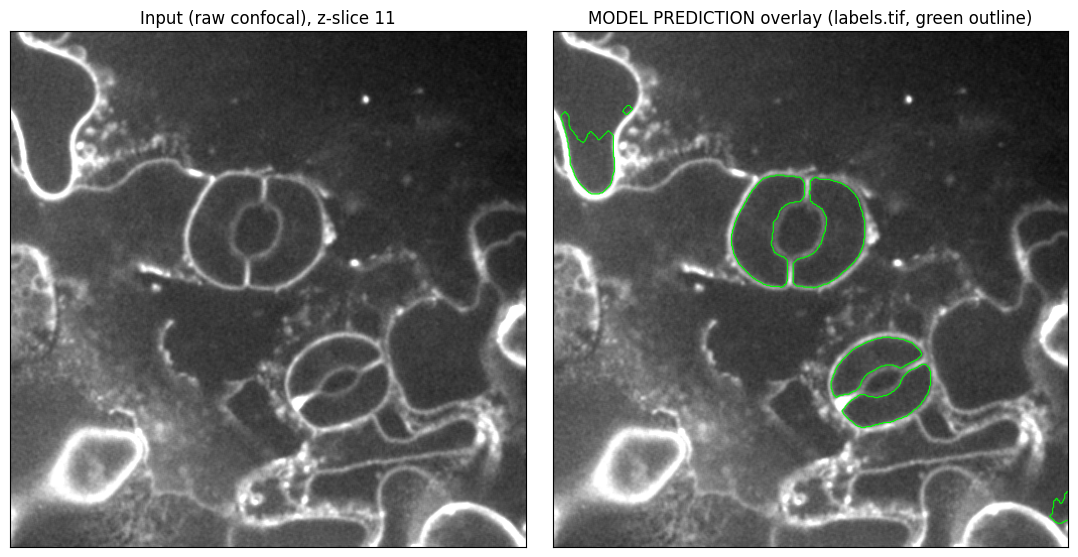

In [ ]:
import pandas as pd
rows = [{'instance': i, 'voxel_count': v, 'volume_x0.02045': round(v * 0.02045, 1)}
        for i, v in inst1]
df1 = pd.DataFrame(rows)
print(df1.to_string(index=False))
df1.to_csv('/content/guard_cell_instances_1-1_after.csv', index=False)
print('saved /content/guard_cell_instances_1-1_after.csv')
zm = vol1.shape[0] // 2
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(vol1[zm], cmap='gray')
axes[0].set_title(f'Input (raw confocal), z-slice {zm}')
axes[1].imshow(vol1[zm], cmap='gray')
axes[1].contour(labels_out1[zm].astype(float), levels=[0.5], colors='lime', linewidths=0.8)
axes[1].set_title('MODEL PREDICTION overlay (labels.tif, green outline)')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Quantitative check on the labeled training volume

Run the identical both-models pipeline on `13.tif` and compare against the expert annotation. **Caveat**: this volume is part of the models' training data, so the score is a *plausibility check of the executed pipeline*, not a test benchmark; the paper's test mIoU (0.824) is not reproduced by a single example. The mask is compared in the original volume space after `resize_back`.

学習ボリューム `13.tif` に同一パイプラインを適用し、専門家アノテーションと IoU/Dice を比較します（学習データを含むため妥当性確認としての意味のみ）。

In [ ]:
z13 = vol13.shape[0]
large13 = resize_to_512((vol13 - vol13.min()) / (vol13.max() - vol13.min()))
t0 = time.time()
p1 = get_prediction(model1, large13, 128, 64)
p2 = get_prediction(model2, large13, 256, 128)
print('13.tif both-models inference:', round(time.time()-t0, 1), 's')
pred13 = resize_back((p1 + p2) / 2, z13)
morphed13 = morph_transformation(pred13, z13)
labels13, N13 = cc3d.connected_components(morphed13, return_N=True)
labels_out13 = cc3d.dust(labels13, threshold=1, connectivity=6, in_place=False)
ref_bin = (np.asarray(lab13) > 0)
prd_bin = (morphed13 > 0)
assert ref_bin.shape == prd_bin.shape, (ref_bin.shape, prd_bin.shape)
inter = int(np.logical_and(ref_bin, prd_bin).sum())
union = int(np.logical_or(ref_bin, prd_bin).sum())
dice = 2 * inter / (int(ref_bin.sum()) + int(prd_bin.sum()))
print(f'reference positive voxels: {int(ref_bin.sum())}')
print(f'predicted positive voxels: {int(prd_bin.sum())}')
print(f'IoU: {inter/union:.4f}   Dice: {dice:.4f}')

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 60ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 54ms/step


1/1 [==============================] - ETA: 0s

...

1/1 [==============================] - 0s 59ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 66ms/step


13.tif both-models inference: 14.5 s


reference positive voxels: 210611
predicted positive voxels: 195003
IoU: 0.8947   Dice: 0.9444


Visualize the comparison on one slice: input, expert reference (red outline) and model prediction (green outline) side by side, plus max-projections of the binary masks.

入力・専門家参照（赤）・モデル予測（緑）を比較表示します。

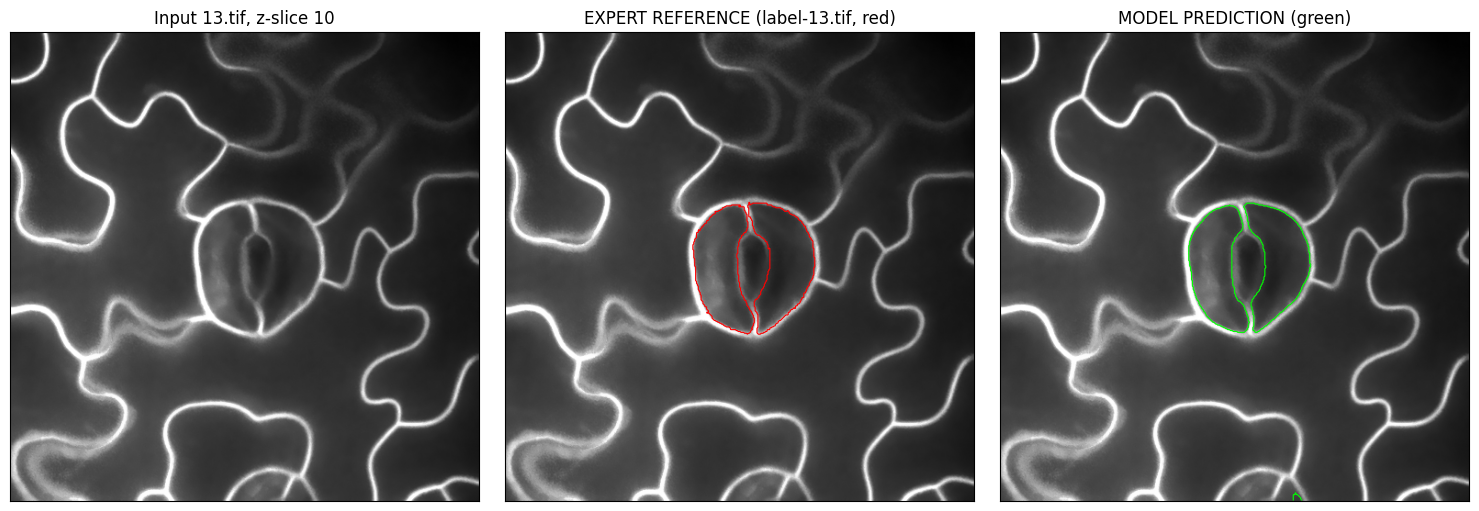

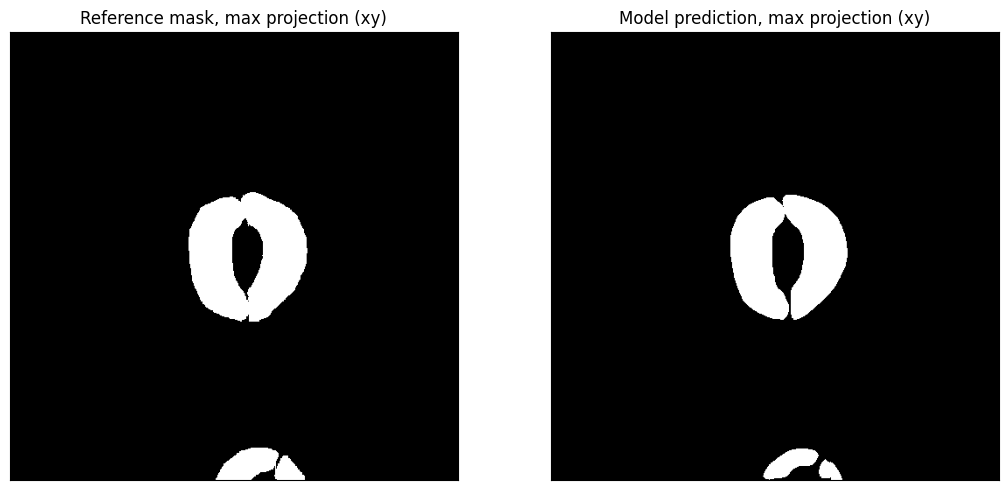

In [ ]:
zm = z13 // 2
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(vol13[zm], cmap='gray')
axes[0].set_title(f'Input 13.tif, z-slice {zm}')
axes[1].imshow(vol13[zm], cmap='gray')
axes[1].contour(ref_bin[zm].astype(float), levels=[0.5], colors='red', linewidths=0.8)
axes[1].set_title('EXPERT REFERENCE (label-13.tif, red)')
axes[2].imshow(vol13[zm], cmap='gray')
axes[2].contour(prd_bin[zm].astype(float), levels=[0.5], colors='lime', linewidths=0.8)
axes[2].set_title('MODEL PREDICTION (green)')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(ref_bin.max(axis=0), cmap='gray')
axes[0].set_title('Reference mask, max projection (xy)')
axes[1].imshow(prd_bin.max(axis=0), cmap='gray')
axes[1].set_title('Model prediction, max projection (xy)')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Interpretation and validation record

- **What was executed**: the authors' pinned inference path (`get_prediction` for patch 128/64 and 256/128, late fusion, `morph_transformation`, `cc3d` instance separation) on two volumes, with all inputs/checkpoints SHA-256-verified. The printed runtimes above come from this actual execution.
- **Which runtime produced the saved outputs**: the validation report for this notebook states the Colab runtime (CPU and/or T4 GPU) and the measured wall times; on a learner runtime your times may differ and free-tier availability varies.
- **Differences from the paper**: training, benchmarks, ablations and the biomechanics statistics are out of scope; the `13.tif` score is a training-sample plausibility check; the 0.02045 volume factor and its unit are the authors' undocumented constant, reported verbatim; the paper's training preprocessing used 3D non-local-means denoising, while the authors' documented inference commands do not enable `--denoise` — this notebook follows the documented inference path.
- **Provenance**: paper Patterns 3(12):100627 (PMC9782259); code github.com/Dolzodmaa/GuardCellSegmentation @ commit `076ffaf8e53c02a0cf44cd9c1c997936e5f4bf92` (MIT); data/checkpoints Mendeley Data 10.17632/2dvtw8cyhx.1 v1 (CC BY 4.0). PhenoPaper investigation/flow records were used as research guidance only.

（実行内容と由来のまとめ。単一例の実行は論文のデータセット精度の検証では ありません。）